In [1]:
library(ggplot2)

In [2]:
df <- read.delim("anomalies.Rin")

Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


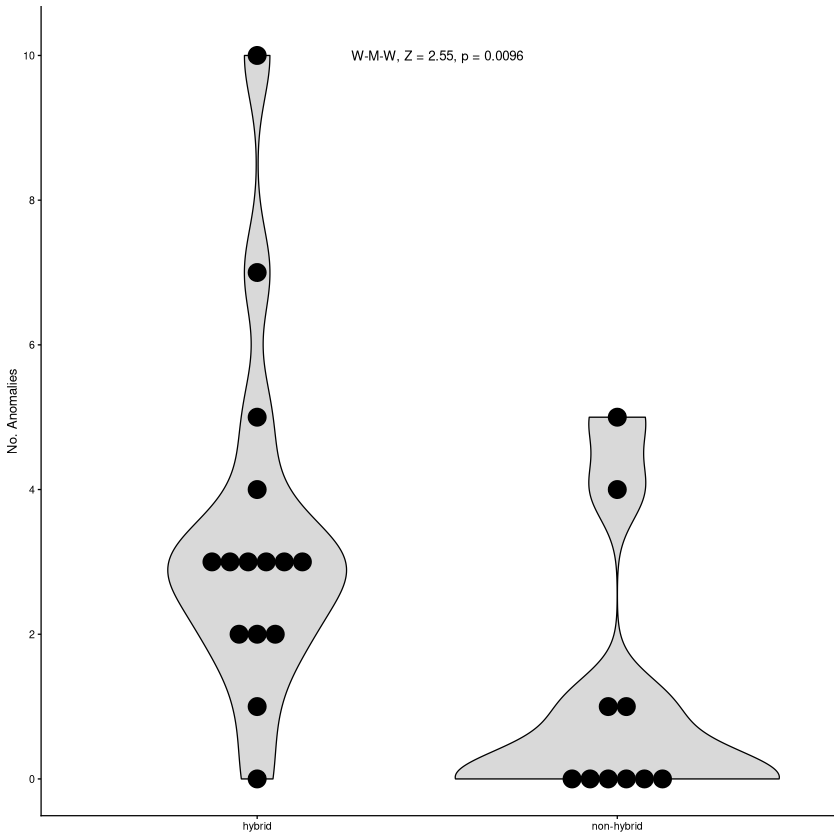

In [3]:
ggplot(df, aes(x = type, y = count)) +
  geom_violin(trim = TRUE, fill = "grey85", color = "black") +
  geom_dotplot(binaxis = "y",
               stackdir = "center",
               dotsize = 0.75,
               fill = "black") +
  annotate("text", x = 1.5, y = max(df$count),
    label = "W-M-W, Z = 2.55, p = 0.0096",
    family = "Helvetica", size = 8/.pt) +

  labs(
    x = NULL,
    y = "No. Anomalies"
  ) +
  theme_classic(base_size = 8, base_family = "Helvetica") +
  coord_cartesian(ylim = c(0, NA)) +
  scale_y_continuous(breaks = c(0,2,4,6,8,10))


In [4]:
ggsave('anomalies_dist.pdf', device = "pdf", width = 1.5, height = 1.5, units = "in")

Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


In [5]:
wilcox.test(count ~ type, data = df)

Warning message in wilcox.test.default(x = DATA[[1L]], y = DATA[[2L]], ...):
“cannot compute exact p-value with ties”



	Wilcoxon rank sum test with continuity correction

data:  count by type
W = 120, p-value = 0.01181
alternative hypothesis: true location shift is not equal to 0


In [6]:
library(coin)
wilcox_test(count ~ factor(type), data = df, distribution = "approximate")

Loading required package: survival




	Approximative Wilcoxon-Mann-Whitney Test

data:  count by factor(type) (hybrid, non-hybrid)
Z = 2.5461, p-value = 0.009
alternative hypothesis: true mu is not equal to 0


In [7]:
library(dplyr)

df |> group_by(type) |> summarise(
  median = median(count),
  Q1 = quantile(count, 0.25),
  Q3 = quantile(count, 0.75)
)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




type,median,Q1,Q3
<chr>,<dbl>,<dbl>,<dbl>
hybrid,3,2,3.5
non-hybrid,0,0,1.0


In [37]:
median(df$count)

[1] 2.5